# 1. Знакомство с данными и их качество

Три файла X5 RetailHero из источника scikit-uplift: `uplift_train` (клиенты эксперимента с группой и target),
`clients` (общая информация о клиентах) и `purchases` (история покупок, одна строка - товар в чеке).
Все агрегаты считаются SQL-запросами из `sql/quality.sql` над вьюхами из `sql/staging.sql`. Вьюха `clients` - даты,
сдвинутые на `CLIENTS_TZ_SHIFT` = 3 часа назад, `clients_raw` - файл как есть; зачем сдвиг, разобрано ниже.
purchases читается из `data/purchases.parquet` (`python -m src.data`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from src import config, db, plots

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
plots.setup()
con = db.connect()

## Колонки

Источник смысла: «sklift» - описание датасета в документации scikit-uplift, «проверено» - сходится с данными
(запросы ниже), «предположение» - вывод по названию и данным. Тип - как его вывел DuckDB, пропуски - доля NULL.

In [2]:
MEANING = {
    ("uplift_train", "client_id"): ("ID клиента, ключ для соединения таблиц", "sklift, проверено"),
    ("uplift_train", "treatment_flg"): ("была ли коммуникация, 0/1", "sklift"),
    ("uplift_train", "target"): ("была ли покупка после коммуникации, 0/1; окно не описано", "sklift"),
    ("clients", "client_id"): ("ID клиента", "sklift, проверено"),
    ("clients", "first_issue_date"): ("выдача карты = первая покупка по карте; на 3 часа позже, чем в purchases", "предположение, проверено"),
    ("clients", "first_redeem_date"): ("первое списание баллов, обычных или экспресс; на 3 часа позже, чем в purchases", "предположение, проверено"),
    ("clients", "age"): ("возраст, есть невозможные значения", "предположение"),
    ("clients", "gender"): ("пол: F, M, U - не указан", "предположение"),
    ("purchases", "client_id"): ("ID клиента", "проверено"),
    ("purchases", "transaction_id"): ("ID чека; уникален только в паре с client_id", "предположение, проверено"),
    ("purchases", "transaction_datetime"): ("время чека", "предположение"),
    ("purchases", "regular_points_received"): ("начислено обычных баллов за чек", "предположение, уровень чека проверен"),
    ("purchases", "express_points_received"): ("начислено экспресс-баллов (акционных) за чек", "предположение, уровень чека проверен"),
    ("purchases", "regular_points_spent"): ("списано обычных баллов за чек, со знаком минус", "предположение, уровень чека проверен"),
    ("purchases", "express_points_spent"): ("списано экспресс-баллов за чек, со знаком минус", "предположение, уровень чека проверен"),
    ("purchases", "purchase_sum"): ("сумма чека до списания баллов", "предположение, проверено"),
    ("purchases", "store_id"): ("ID магазина", "предположение"),
    ("purchases", "product_id"): ("ID товара; справочника товаров в источнике нет", "предположение"),
    ("purchases", "product_quantity"): ("количество; 0 у 5,9% строк, почти все с ненулевой суммой", "предположение"),
    ("purchases", "trn_sum_from_iss"): ("сумма строки, оплаченная деньгами, округлена до рубля", "предположение, проверено"),
    ("purchases", "trn_sum_from_red"): ("сумма строки до списания баллов; только в чеках со списанием", "предположение, проверено"),
}
types = pd.concat([
    con.execute(f"describe {t}").df().assign(tbl=t)[["tbl", "column_name", "column_type"]]
    for t in ["uplift_train", "clients", "purchases"]
])
nulls = db.run(con, "quality.sql", "nulls").rename(columns={"name": "column_name", "value": "null_share"})
profile = types.merge(nulls, on=["tbl", "column_name"])
profile["meaning"] = [MEANING[k][0] for k in zip(profile.tbl, profile.column_name)]
profile["source"] = [MEANING[k][1] for k in zip(profile.tbl, profile.column_name)]
profile.round({"null_share": 4})

,tbl,column_name,column_type,null_share,meaning,source
0,uplift_train,client_id,VARCHAR,0.0000,"ID клиента, ключ для соединения таблиц","sklift, проверено"
1,uplift_train,treatment_flg,BIGINT,0.0000,"была ли коммуникация, 0/1",sklift
2,uplift_train,target,BIGINT,0.0000,"была ли покупка после коммуникации, 0/1; окно не описано",sklift
3,clients,client_id,VARCHAR,0.0000,ID клиента,"sklift, проверено"
4,clients,first_issue_date,TIMESTAMP,0.0000,"выдача карты = первая покупка по карте; на 3 часа позже, чем в purchases","предположение, проверено"
5,clients,first_redeem_date,TIMESTAMP,0.0886,"первое списание баллов, обычных или экспресс; на 3 часа позже, чем в purchases","предположение, проверено"
6,clients,age,BIGINT,0.0000,"возраст, есть невозможные значения",предположение
7,clients,gender,VARCHAR,0.0000,"пол: F, M, U - не указан",предположение
8,purchases,client_id,VARCHAR,0.0000,ID клиента,проверено
9,purchases,transaction_id,VARCHAR,0.0000,ID чека; уникален только в паре с client_id,"предположение, проверено"


Пропуски только в двух колонках: `first_redeem_date` (8,86%, клиент ни разу не списывал баллы, предположение)
и `trn_sum_from_red` (93,35% строк, поле заполнено только в чеках со списанием баллов, см. ниже).

## Сверка с описанием датасета

В документации scikit-uplift: 200 039 клиентов в `uplift_train`, 400 162 в `clients`, 45 786 568 строк в `purchases`,
доля target 0,62, доля treatment 0,5.

In [3]:
overview = db.run(con, "quality.sql", "overview")
overview["expected"] = [200_039, 400_162, 45_786_568]
overview

,tbl,n_rows,n_clients,expected
0,uplift_train,200039,200039,200039
1,clients,400162,400162,400162
2,purchases,45786568,400162,45786568


In [4]:
db.run(con, "quality.sql", "train_shares")

,n,target_share,treatment_share,t1_y1,t1_y0,t0_y1,t0_y0
0,200039,0.619889,0.499808,63639,36342,60363,39695


Размеры совпадают, доля target 0,6199, доля treatment 0,4998. Все 400 162 клиента из `clients` есть в purchases.
Судя по числу, вторая половина `clients` - тест хакатона без target, его в источнике нет.

## Ключи и дубли

In [5]:
db.run(con, "quality.sql", "purchases_keys")

,n_transactions,n_transaction_ids,n_stores,n_products,first_dt,last_dt
0,8045229,8045201,13882,42530,2018-11-21 21:02:33,2019-03-18 23:40:03


In [6]:
db.run(con, "quality.sql", "duplicates")

,train_dup_client,clients_dup_client,purchases_dup_rows,purchases_dup_line_key
0,0,0,0,0


In [7]:
db.run(con, "quality.sql", "transaction_id_collisions")

,n_transaction_ids,max_clients
0,28,2


Полных дублей нет. Чеков 8 045 229, а значений `transaction_id` 8 045 201: 28 значений встречаются у двух разных
клиентов в разные дни и в разных магазинах. Похоже на совпадения при анонимизации ID (предположение). Поэтому чек
везде - пара (client_id, transaction_id), а строка - тройка (client_id, transaction_id, product_id), по ней дублей нет.

In [8]:
db.run(con, "quality.sql", "key_coverage")

,train_not_in_clients,train_not_in_purchases,purchases_not_in_clients,clients_not_in_purchases
0,0,0,0,0


Все клиенты `uplift_train` есть и в `clients`, и в purchases. Лишних клиентов в purchases нет.

## Поля уровня чека

Время, магазин, `purchase_sum` и баллы повторяются в каждой строке чека. Проверяю, что внутри чека они постоянны.

In [9]:
db.run(con, "quality.sql", "transaction_consistency")

,n_transactions,dt,store_id,purchase_sum,regular_points_received,express_points_received,regular_points_spent,express_points_spent
0,8045229,0,0,0,0,0,0,0


Внутри чека все восемь полей постоянны. Значит, суммировать их по строкам нельзя: в признаках беру их один раз
на чек.

## purchase_sum и суммы строк

`trn_sum_from_iss` всегда целое, а у `purchase_sum` есть копейки, поэтому «совпадает» считаю с точностью 0,5 руб.
на строку.

In [10]:
db.run(con, "quality.sql", "purchase_sum_vs_lines")

,has_points_spent,has_red_lines,n_transactions,ps_eq_iss,ps_eq_red,red_minus_iss_eq_points_spent,all_lines_have_red
0,False,False,7538988,0.899901,0.000665,0.000699,0.00000
1,False,True,1644,0.858881,0.861314,0.998175,1.00000
2,True,False,5,0.000000,0.000000,0.000000,0.00000
3,True,True,504592,0.037192,0.864366,0.953023,0.99997


- В чеках без списания баллов (7 538 988, 93,7%) `purchase_sum` совпадает с суммой `trn_sum_from_iss` в 90,0% чеков.
  Остальные 10% разобраны ниже.
- В чеках со списанием (504 592) с суммой `trn_sum_from_iss` совпадает только 3,7%, а с суммой `trn_sum_from_red` - 86,4%.
  Разница `trn_sum_from_red - trn_sum_from_iss` равна списанным баллам в 95,3% чеков.
- Отсюда предположение: `purchase_sum` - сумма чека до списания баллов, `trn_sum_from_iss` - часть строки,
  оплаченная деньгами, `trn_sum_from_red` - сумма строки до списания, заполняется только при списании.
  Один балл - один рубль (тоже предположение).

Для признаков беру `purchase_sum` на уровне чека: он не зависит от того, списывал ли клиент баллы.

Допуск растёт с числом строк, потому что каждая строка округлена до рубля. С фиксированным допуском 1 руб. гипотеза
`purchase_sum` = сумма `trn_sum_from_iss` не сходится в 46,3% чеков, но из них 30,7 п.п. - чеки без списания,
где разница укладывается в округление строк, и 6,2 п.п. - чеки со списанием, где сумма другая по смыслу.
В чеках без списания баллов сумма чека и сумма строк расходятся больше чем на 5 руб. в 3,1% всех чеков (последняя колонка).

In [11]:
db.run(con, "quality.sql", "purchase_sum_tolerance")

,n_transactions,share_mismatch_1rub,with_points_spent,no_spend_within_rounding,no_spend_beyond_rounding,no_spend_diff_gt_5rub
0,8045229,0.463083,0.061907,0.307347,0.093829,0.031229


Чеки без списания, где разница больше округления: насколько она велика.

In [12]:
db.run(con, "quality.sql", "purchase_sum_mismatch_size")

,n_transactions,median_abs_rub,p95_abs_rub,median_rel,p95_rel,share_le_5rub,share_purchase_sum_greater,median_lines
0,754645,1.0,258.32,0.025,0.581239,0.667405,0.332593,1.0


Таких чеков 754 645 (9,4% всех). Обычно расхождение мелкое: медиана 1 руб. и 2,5% суммы чека, у 66,7% - не больше
5 руб. Но хвост есть: p95 - 258 руб. и 58% суммы. Чаще это чеки из одной строки, и в 67% сумма строк больше
`purchase_sum`. Причину по данным не нашёл, возможно, скидки или удалённые строки (предположение). На признаки это
не влияет: суммы строк я не использую.

In [13]:
db.run(con, "quality.sql", "line_values")

,n_lines,iss_not_integer,ps_not_integer,qty_0,qty_0_sum_positive,qty_fraction,iss_0,ps_0
0,45786568,0,21448403,2707278,2699197,0,713255,620


`product_quantity` - всегда целое. 2 707 278 строк (5,9%) с количеством 0, и у 99,7% из них сумма больше нуля.
Похоже на весовые товары (предположение), поэтому количество в признаки не беру, считаю строки и уникальные товары.
620 строк (567 чеков) с `purchase_sum` = 0.

## Возраст и пол

In [14]:
age_bins = db.run(con, "quality.sql", "age_bins")
age_bins

,age_bin,n_clients,n_train
0,< 0,96,56
1,0 - 13,634,306
2,14 - 100,398383,199156
3,> 100,1049,521


In [15]:
db.run(con, "quality.sql", "age_spikes")

,age,n_clients
0,115,405
1,119,397
2,944,7
3,949,7
4,952,6


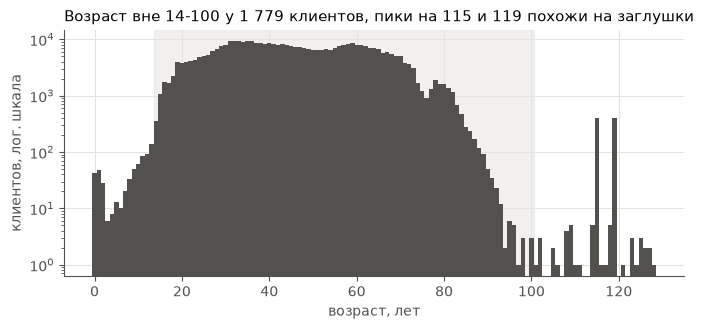

In [16]:
age = db.run(con, "quality.sql", "age_hist")
bad = age_bins.query("age_bin != '14 - 100'")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(age.age, age.n_clients, width=1, color=plots.INK)
ax.axvspan(config.AGE_MIN - 0.5, config.AGE_MAX + 0.5, color=plots.GRID, alpha=0.5, zorder=0)
ax.set_yscale("log")
ax.set_xlabel("возраст, лет")
ax.set_ylabel("клиентов, лог. шкала")
n_bad = f"{bad.n_clients.sum():,}".replace(",", " ")
ax.set_title(f"Возраст вне {config.AGE_MIN}-{config.AGE_MAX} у {n_bad} клиентов, пики на 115 и 119 похожи на заглушки")
plt.show()

Возраст вне 14-100 лет у 1 779 клиентов, из них 883 в `uplift_train`. Это меньше 0,5%. Ниже 14 лет и выше 100 лет
считаю ошибкой и в витрине признаков заменяю на NULL (границы в `src/config.py`). Пики на 115 и 119 годах похожи
на заглушки при заполнении анкеты (предположение). От 14 лет число клиентов растёт плавно, поэтому нижняя граница 14.

In [17]:
db.run(con, "quality.sql", "gender")

,gender,n_clients,share
0,F,147649,0.368973
1,M,66807,0.166950
2,U,185706,0.464077


Пол не указан у 46,4% клиентов, `U` оставляю отдельной категорией.

## Даты в clients

In [18]:
db.run(con, "quality.sql", "client_dates")

,n_clients,redeem_null,redeem_before_issue,issue_after_history,redeem_after_cutoff,min_issue,max_issue,max_redeem
0,400162,35469,536,0,44953,2017-04-04 15:24:18,2019-03-15 18:50:56,2019-11-19 22:14:10


Даты здесь уже сдвинуты. Карты выданы с 2017-04-04 по 2019-03-15, позже конца истории покупок - ни одной. У 536 клиентов
первое списание раньше выдачи карты - аномалия, их немного. `first_redeem_date` позже `CUTOFF` у 44 953 клиентов,
вплоть до 2019-11-19 22:14 (в исходном файле 2019-11-20 01:14).

### Сдвиг на 3 часа

Если `first_redeem_date` - первое списание баллов, то списаний раньше неё в purchases быть не должно. Проверяю
по исходным датам и после сдвига.

In [19]:
db.run(con, "quality.sql", "spent_before_redeem")

,n_clients,spend_before_redeem_raw,spend_before_redeem_shifted
0,72752,72411,0


In [20]:
db.run(con, "quality.sql", "clients_time_offset")

,what,n_clients,exactly_3h,from_2h_to_3h,negative,no_event,more_than_3h
0,first_issue_date - первая покупка,47230,46710,25,82,0,408
1,first_redeem_date - первое списание обычных баллов,72752,70685,183,771,1107,0


По исходным датам списание раньше `first_redeem_date` есть у 72 411 из 72 752 клиентов, у которых дата попадает
в окно истории. Но разница почти всегда ровно 3 часа: у 70 685 клиентов (97,2%) `first_redeem_date` ровно на 3 часа
позже первого списания обычных баллов. То же с `first_issue_date`: ровно 3 часа после первой покупки у 46 710
из 47 230 клиентов (98,9%). Похоже, даты в `clients` записаны в другом часовом поясе, например по Москве, а purchases -
по UTC (предположение). После сдвига на -3 часа списаний раньше `first_redeem_date` нет ни у одного клиента.

Обратная проверка: у клиентов, чья сдвинутая дата попадает в окно с 2018-11-21 по `CUTOFF`, есть ли в purchases
событие ровно в этот момент. Порог, при котором оставляю сдвиг и признак, - 95%.

In [21]:
db.run(con, "quality.sql", "shift_reverse_check")

,check_,n_clients,share_exact,share_1min
0,first_redeem_date: чек со списанием любых баллов,73119,0.988430,0.988539
1,first_redeem_date: чек со списанием обычных баллов,73119,0.966712,0.966890
2,first_issue_date: первая покупка,47662,0.980026,0.988020


Чек со списанием баллов ровно в сдвинутый момент `first_redeem_date` есть у 98,8% клиентов, с допуском в минуту
почти столько же. Если учитывать только обычные баллы - 96,7%: разница в экспресс-баллах. Первая покупка ровно
в сдвинутый момент `first_issue_date` - у 98,0%, с допуском в минуту - у 98,8%. Оба значения выше порога 95%,
поэтому сдвиг оставляю.

Остаток первой проверки - 2 067 клиентов (2,8%), у которых разница с первым списанием обычных баллов не ровно 3 часа.

In [22]:
db.run(con, "quality.sql", "shift_residual")

,grp,n_clients,lag_hours_q,exact_spend_after_shift,exact_express_only
0,нет списаний обычных баллов,1107,<NA>,948,948
1,обычные баллы списаны позже redeem,771,"[-2011.261389, -501.831389, -20.734167]",589,589
2,разница от 2 до 3 часов,189,"[2.361722, 2.956389, 2.986111]",51,51


У 1 588 из 2 067 после сдвига ровно в этот момент есть чек, где списаны только экспресс-баллы. Значит,
`first_redeem_date` - первое списание любых баллов, а не только обычных. Без объяснения остаются 479 клиентов
(0,66% из 72 752): у 138 сдвинутая дата раньше первого видимого списания не больше чем на 47 минут, у 182 первое
списание обычных баллов позже (медиана 21 день), у 159 списаний обычных баллов в истории нет. Ни у кого из 479
в сдвинутый момент списания нет. Похоже, части чеков в purchases нет (предположение).

In [23]:
db.run(con, "quality.sql", "redeem_after_cutoff_by_month")

,month,n_clients
0,2019-03-01,9802
1,2019-04-01,9602
2,2019-05-01,7129
3,2019-06-01,5616
4,2019-07-01,4607
5,2019-08-01,2570
6,2019-09-01,2285
7,2019-10-01,2064
8,2019-11-01,1278


Сдвиг на 3 часа не меняет число клиентов с `first_redeem_date` после 2019-03-18: их 44 953 и до, и после сдвига. Таких
дат больше всего в марте и апреле, потом всё меньше. То есть `clients` выгружен не раньше 20 ноября 2019 и содержит
события после коммуникации. Поэтому и `age`, и `gender` - состояние на момент выгрузки, а не на момент коммуникации. На этапе 2 сравню долю таких клиентов между treatment и control.

## История покупок по дням

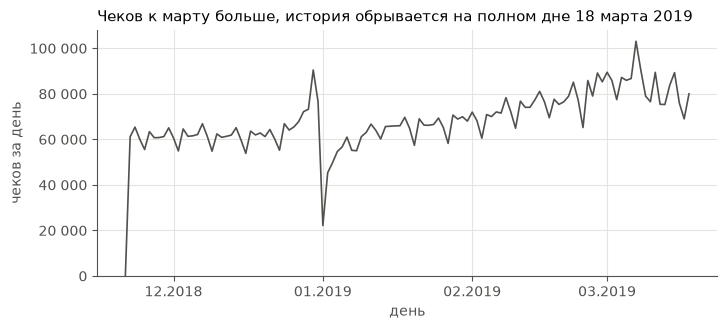

,day,n_transactions,n_clients
0,2018-11-21,32,30
1,2018-11-22,61181,54584
116,2019-03-17,69015,60698
117,2019-03-18,79976,70273


In [24]:
daily = db.run(con, "quality.sql", "daily")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(daily.day, daily.n_transactions, color=plots.INK, lw=1.2)
plots.thousands(ax.yaxis)
ax.set_ylim(0)
ax.set_xlabel("день")
ax.set_ylabel("чеков за день")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
ax.set_title("Чеков к марту больше, история обрывается на полном дне 18 марта 2019")
plt.show()
daily.iloc[[0, 1, -2, -1]]

In [25]:
db.run(con, "quality.sql", "train_history")

,n_clients,n_trn_q,one_transaction,last_purchase_on_last_day,no_purchases_last_30d,max_days_since_last
0,200039,"[3.0, 8.0, 15.0, 27.0, 54.0]",3820,35273,0,22


In [26]:
db.run(con, "quality.sql", "activity_window")

,in_experiment,n_clients,earliest_last_purchase,latest_last_purchase
0,True,200039,2019-02-24,2019-03-18
1,False,200123,2019-02-25,2019-03-18


История начинается вечером 2018-11-21 (32 чека, неполный день) и идёт до 2019-03-18 23:40. Чеков за день становится больше: около 60 тысяч в декабре и 75-90 тысяч в марте, пики 31 декабря и 7 марта, провал 1 января. Последний день - полный
по числу чеков (79 976). У клиентов `uplift_train` медиана 15 чеков, у 3 820 клиентов чек один. Окно активности: все клиенты покупали хотя бы раз в окне с 2019-02-24 по 2019-03-18.
Самая ранняя последняя покупка у клиентов эксперимента - 2019-02-24, у остальных клиентов `clients` - 2019-02-25.
Похоже, в датасет отбирали недавно активных клиентов (предположение).

## Итоги

- Таблицы сходятся с описанием: 200 039 / 400 162 / 45 786 568 строк, target 0,62, treatment 0,50.
  Дублей нет, все клиенты эксперимента есть в истории покупок.
- Чек - пара (client_id, transaction_id). Поля чека постоянны внутри чека, агрегирую их один раз на чек.
- Сумму чека беру из `purchase_sum`. Количество не беру: у 5,9% строк оно 0 при ненулевой сумме.
- Возраст вне 14-100 у 1 779 клиентов (883 в эксперименте) - в витрине NULL.
- Даты в `clients` на 3 часа позже, чем в purchases. Сдвиг в `staging.sql` (`CLIENTS_TZ_SHIFT` в `config.py`).
  После сдвига `first_redeem_date` - первое списание любых баллов: обратная проверка 98,8%, для `first_issue_date`
  и первой покупки 98,0%. Признаки `redeemed_before_cutoff` и `days_issue_to_redeem` можно использовать.
- Дату коммуникации и окно target по данным не установить. Косвенно: история обрывается на полном дне
  2019-03-18, карт после 2019-03-15 нет, все клиенты покупали хотя бы раз в окне с 2019-02-24 по 2019-03-18. А `clients` выгружен
  не раньше 2019-11-20 и содержит события после коммуникации: `first_redeem_date` до 2019-11-20. Расхождение
  групп в последние дни истории проверю на этапе 2.